# Exploration RSNA Knee Abnormality Detection

CSV Kaggle + volumes NPZ locaux `(24, 224, 224)` uint8.

On ne dézippe pas `data/volumes.zip` : les `.npz` sont lus dans l’archive.

In [1]:
from pathlib import Path
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

CSV = ROOT / "data" / "csv"
VOLUMES = ROOT / "data" / "volumes.zip"

LABELS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

print("CSV:", CSV)
print("volumes:", VOLUMES, "exists=", VOLUMES.exists())

CSV: c:\Users\sulta\Documents\RSNA-comp\data\csv
volumes: c:\Users\sulta\Documents\RSNA-comp\data\volumes.zip exists= True


In [2]:
train = pd.read_csv(CSV / "train.csv")
series = pd.read_csv(CSV / "train_series.csv")
test = pd.read_csv(CSV / "test.csv")
test_series = pd.read_csv(CSV / "test_series.csv")
sub = pd.read_csv(CSV / "sample_submission.csv")

labeled = train.dropna(subset=LABELS, how="all")
n_fully = train[LABELS].notna().all(axis=1).sum()

print(f"études train     : {len(train):,}")
print(f"séries train     : {len(series):,}")
print(f"études avec ≥1 label : {len(labeled):,}  ({100*len(labeled)/len(train):.1f}%)")
print(f"études 12 labels     : {n_fully:,}")
print(f"test exemple         : {len(test)} études / {len(test_series)} séries")
print(f"séries / étude       : médiane {series.groupby('StudyInstanceUID').size().median():.0f}")

études train     : 4,407
séries train     : 24,371
études avec ≥1 label : 58  (1.3%)
études 12 labels     : 58
test exemple         : 3 études / 15 séries
séries / étude       : médiane 5


## Labels (sous-ensemble annoté)

La plupart des études n’ont **pas** les 12 cibles : seuls les rapports sont fournis. Le modèle est évalué en macro-AUC sur ces 12 labels.

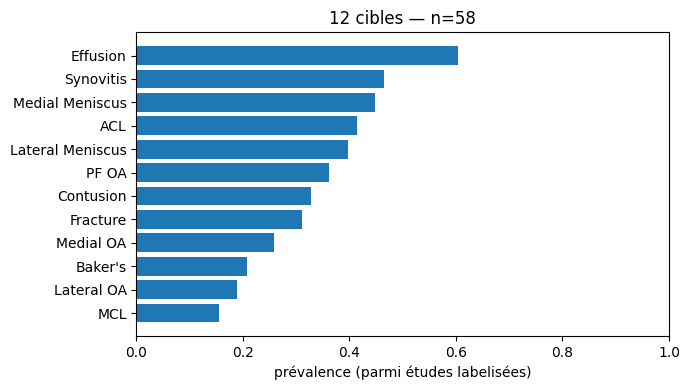

,MCL,Lateral OA,Baker's,Medial OA,Fracture,Contusion,PF OA,Lateral Meniscus,ACL,Medial Meniscus,Synovitis,Effusion
prevalence,0.155,0.19,0.207,0.259,0.31,0.328,0.362,0.397,0.414,0.448,0.466,0.603


In [3]:
prev = labeled[LABELS].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(prev.index, prev.values)
ax.set_xlabel("prévalence (parmi études labelisées)")
ax.set_xlim(0, 1)
ax.set_title(f"12 cibles — n={len(labeled):,}")
plt.tight_layout()
plt.show()

display(prev.to_frame("prevalence").T.round(3))

## Séries MRI

plan anatomique
Anatomical_Plane
Sagittal    9864
Coronal     8609
Axial       5898

Fluid_Sensitive x Fat_Suppression


Fat_Suppression,0,1
Fluid_Sensitive,,
0,10361,0
1,0,14010


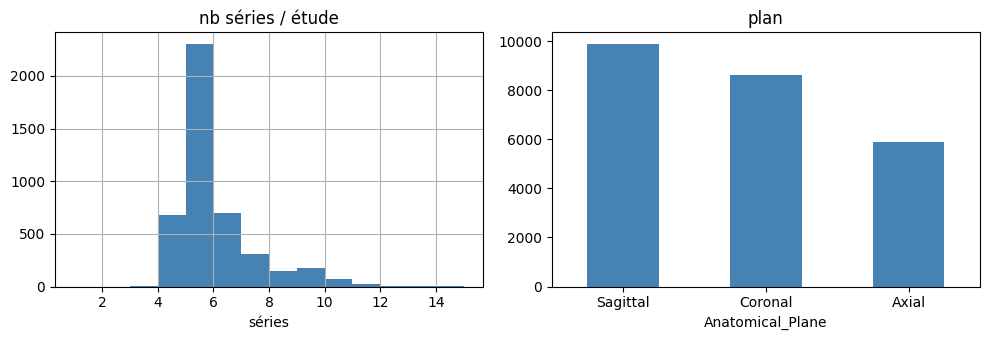

In [4]:
print("plan anatomique")
print(series["Anatomical_Plane"].value_counts().to_string())
print("\nFluid_Sensitive x Fat_Suppression")
display(pd.crosstab(series["Fluid_Sensitive"], series["Fat_Suppression"]))

per_study = series.groupby("StudyInstanceUID").size()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
per_study.hist(bins=range(1, int(per_study.max()) + 2), ax=axes[0], color="steelblue")
axes[0].set_title("nb séries / étude")
axes[0].set_xlabel("séries")
series["Anatomical_Plane"].value_counts().plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("plan")
plt.tight_layout()
plt.show()

## Volumes NPZ

Un fichier par `SeriesInstanceUID`, clé `data`, shape uniforme `(24, 224, 224)` uint8.

In [5]:
z = zipfile.ZipFile(VOLUMES)
npz_ids = {Path(n).stem for n in z.namelist() if n.endswith(".npz")}
series_ids = set(series["SeriesInstanceUID"])

print(f"npz dans le zip     : {len(npz_ids):,}")
print(f"séries train.csv    : {len(series_ids):,}")
print(f"séries sans npz     : {len(series_ids - npz_ids):,}")
print(f"npz hors train      : {len(npz_ids - series_ids):,}")

sample_uid = series["SeriesInstanceUID"].iloc[0]
vol = np.load(io.BytesIO(z.read(f"{sample_uid}.npz")))["data"]
print(f"\nexemple {sample_uid[-12:]}")
print(f"shape={vol.shape}  dtype={vol.dtype}  min={vol.min()} max={vol.max()}")

npz dans le zip     : 24,371
séries train.csv    : 24,371
séries sans npz     : 0
npz hors train      : 0

exemple 715412333772
shape=(24, 224, 224)  dtype=uint8  min=0 max=249


étude: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
positifs: ['PF OA', 'Effusion']
rapport (200 car.):
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marg


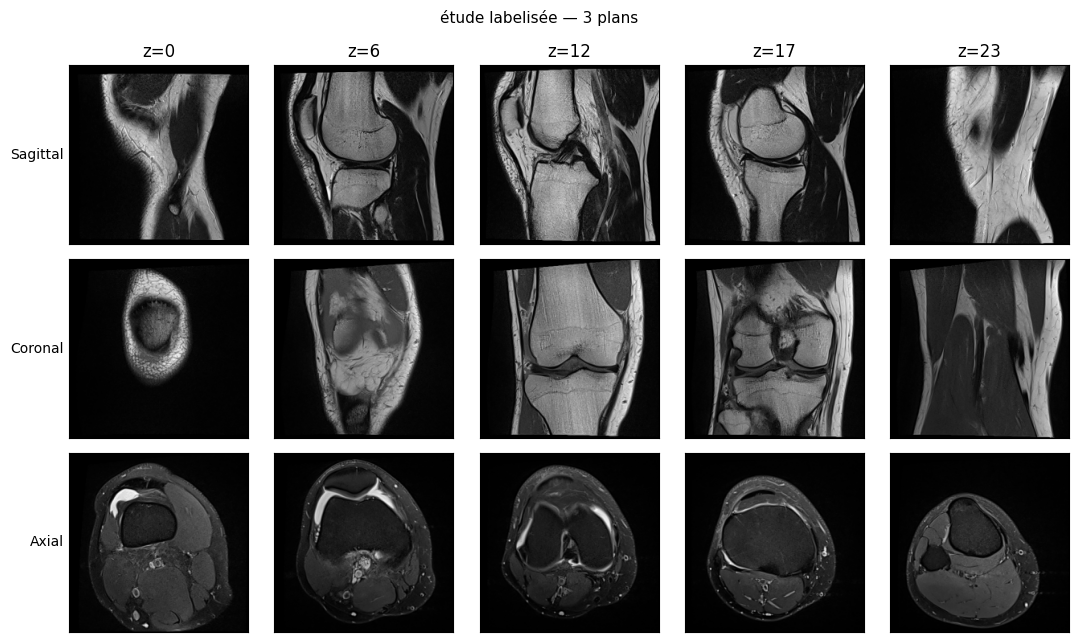

In [6]:
def load_vol(uid: str) -> np.ndarray:
    return np.load(io.BytesIO(z.read(f"{uid}.npz")))["data"]


def show_study(study_uid: str, title: str = ""):
    rows = series[series["StudyInstanceUID"] == study_uid]
    planes = ["Sagittal", "Coronal", "Axial"]
    fig, axes = plt.subplots(len(planes), 5, figsize=(11, 6.5))
    mid = 12  # 24 coupes → centre
    idxs = [0, 6, mid, 17, 23]
    for i, plane in enumerate(planes):
        hit = rows[rows["Anatomical_Plane"] == plane]
        axrow = axes[i] if len(planes) > 1 else [axes]
        if hit.empty:
            for ax in axrow:
                ax.axis("off")
            axrow[0].set_ylabel(plane, rotation=0, ha="right", va="center")
            continue
        vol = load_vol(hit["SeriesInstanceUID"].iloc[0])
        for ax, j in zip(axrow, idxs):
            ax.imshow(vol[j], cmap="gray")
            ax.set_xticks([])
            ax.set_yticks([])
            if i == 0:
                ax.set_title(f"z={j}")
        axrow[0].set_ylabel(plane, rotation=0, ha="right", va="center")
    fig.suptitle(title or study_uid[-20:], fontsize=11)
    plt.tight_layout()
    plt.show()


study = labeled["StudyInstanceUID"].iloc[0] if len(labeled) else train["StudyInstanceUID"].iloc[0]
row = train.set_index("StudyInstanceUID").loc[study]
pos = [c for c in LABELS if pd.notna(row[c]) and row[c] == 1]
print("étude:", study)
print("positifs:", pos or "(aucun / non labelisé)")
print("rapport (200 car.):")
print(str(row["Report"])[:200])
show_study(study, title="étude labelisée — 3 plans")